# Models supervisats en Pytorch

En xarxes neuronals es poden resoldre els mateixos problemes que en `machine learning`. Es poden arribar a millors resultats en molts casos a costa d'un major cost d'entrenament i d'inferència. A més, necessiten més dades d'entrenament per a obtenir bons resultats. 

Problemes que són massa complexos per a arbres de decisió o models lineals poden ser resolts amb xarxes neuronals. Per exemple, distinguir una persona d'una altra en una foto o traduir textos. 

## Representació de dades en tensors

### Representar dades tabulars

La majoria dels problemes que hem vist a machine learning eren datasets en csv o similars. Les transformacions són les mateixes: One-hot encoding, Label encoding,  normalització o estandarització. 

Però en les dades tabulars en Deep Learning ens podem trobar amb **textos** que no poden organitzar-se en categories. Per convertir els textos en números hem de aplicar tècniques de `NLP`. Transformar els textos a columnes numèriques es diu `embedding` i es fa amb models preentrenats basat en `Recurrent Neural Networks` `RNN`, `LSTM` o `Transformers`.  Ho veurem més endavant. 

### Treballant amb imatges

Una imatge és representada com una col·lecció d'escalars en una quadricula bidimensional amb unes medides concretes. Es poden tenir un o més escalars en cada píxel representant l'escala de grisos, RGB o altres representacions del color. Normalment comptem amb 8 bits per color, encara que algunes imatges mèdiques o industrials poden tenir 10, 12 o 16 bits de profunditat de color. 

És molt fàcil importar una imatge en python:

In [4]:

from PIL import Image
import numpy as np

import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F

img = Image.open('perro.jpg')
img_arr = np.array(img)
print(type(img))
print(img_arr.shape)
print(type(img_arr))

<class 'PIL.JpegImagePlugin.JpegImageFile'>
(900, 900, 3)
<class 'numpy.ndarray'>


Pytorch necessita les imatges en un altre layout: Channels, Heigth, Width. L'operació de permutació és molt "barata", ja que no fa copia, juga amb el layout al nivell de tensor. 

In [5]:
img = torch.from_numpy(img_arr)
out = img.permute(2, 0, 1)

Les xarxes neuronals treballen millor si l'entrada és un número entre 0 i 1, per tant, cal normalitzar els 8 bits (0-255) a eixos valors

In [7]:
#normalized = out.float() / 255.0
#mean = out.mean(dim=[1, 2])
#std = out.std(dim=[1, 2])
#standardized = (normalized - mean[:, None, None]) / std[:, None, None]

## Regressió

Als exemples que s'han vist en l'introducció a Pytorch hen resolt sempre un problema de regressió lineal. Amb xarxes neuronals no hi ha molta diferència entre algorismes, sino en la arquitectura de les capes i les funcions d'activació. D'aquesta manera no es solen fer arbres de decisió o búsqueda de veïns amb xarxes neuronals. Tots els problemes es descomposen en moltes regressions lineals amb distintes funcions d'activació i distinta manera de connectar eixes regressions (perceptrons). 

L'única diferència amb la classificació, per tant, és la funció d'activació final i la funció de pèrdua (loss). En el cas de regressió el més habitual serà fer una capa lineal d'una eixida sense funció d'activació final. 

## Classificació

Fer una classificació en xarxes neuronals implica aplicar una capa d'activació a l'última capa. Si es tracta d'una classificació binària es pot posar una funció sigmoide. En el cas de classificació multiclasse es pot acabar en una capa `lineal` de varies eixides (`logits`) i després fer un `softmax`. 

Anem a veure un exemple de classificació d'imatges simplificat tant en les imatges com en la xarxa proposada. L'interés està més en com organitzar l'entrenament que en el tractament d'imatges. 

Font: https://github.com/dvgodoy/PyTorchStepByStep/blob/master/Chapter04.ipynb 

In [33]:
import random
import numpy as np
from PIL import Image


import torch
import torch.optim as optim
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader, Dataset, random_split, WeightedRandomSampler, SubsetRandomSampler
from torchvision.transforms.v2 import Compose, ToTensor, Normalize, ToPILImage, RandomHorizontalFlip, Resize, ToImage, ToDtype

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
%matplotlib inline

torch.manual_seed(42)

Utilitzarem una funció externa per generar imatges de dos classes: Diagonals i Horitzontals. Es tracta d'imatges de 5x5. 

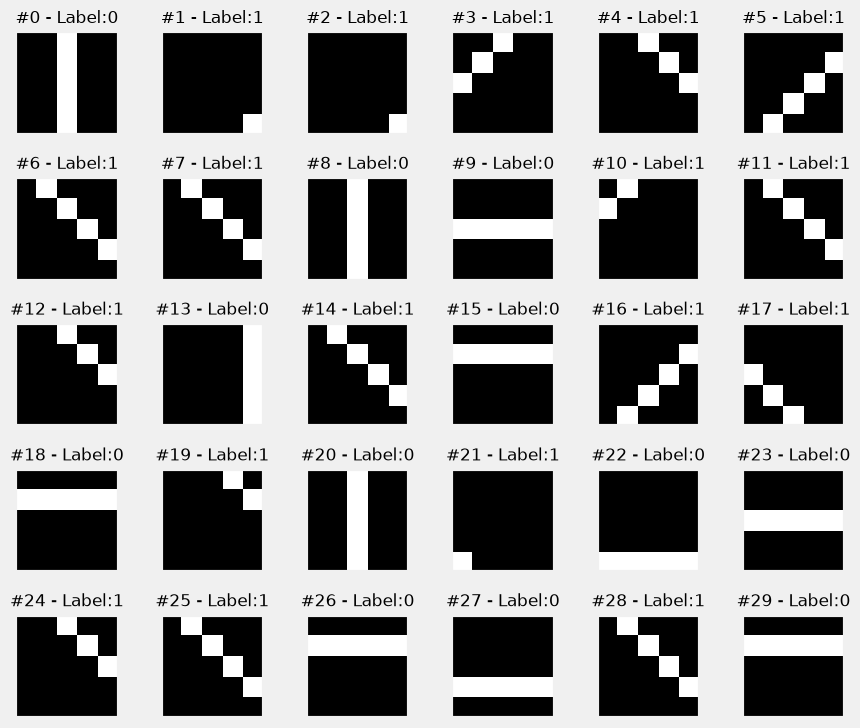

In [34]:
from image_generation import generate_dataset

images, labels = generate_dataset(img_size=5, n_images=300, binary=True, seed=13)

def plot_images(images, targets, n_plot=30):
    n_rows = n_plot // 6 + ((n_plot % 6) > 0)
    fig, axes = plt.subplots(n_rows, 6, figsize=(9, 1.5 * n_rows))
    axes = np.atleast_2d(axes)
    
    for i, (image, target) in enumerate(zip(images[:n_plot], targets[:n_plot])):
        row, col = i // 6, i % 6    
        ax = axes[row, col]
        ax.set_title('#{} - Label:{}'.format(i, target), {'size': 12})
        # plot filter channel in grayscale
        ax.imshow(image.squeeze(), cmap='gray', vmin=0, vmax=1)

    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.label_outer()

    plt.tight_layout()
    return fig



fig = plot_images(images, labels, n_plot=30)


In [35]:
images.shape, type(images)

((300, 1, 5, 5), numpy.ndarray)

La forma d'aquest array és adequada a Pytorch amb 300 mostres d'un canal (escala de grisos) de 5x5 pixels. 

Si Observem l'exemple 7 vorem que els píxels blancs tenen valor 255. 

In [36]:
example = images[7]
example

array([[[  0, 255,   0,   0,   0],
        [  0,   0, 255,   0,   0],
        [  0,   0,   0, 255,   0],
        [  0,   0,   0,   0, 255],
        [  0,   0,   0,   0,   0]]], dtype=uint8)

Anem a generar els datasets en tensors i el `Dataset`:

In [37]:
x_tensor = torch.as_tensor(images / 255).float()
y_tensor = torch.as_tensor(labels.reshape(-1, 1)).float()



class TransformedTensorDataset(Dataset):
    def __init__(self, x, y, transform=None):
        self.x = x
        self.y = y
        self.transform = transform
        
    def __getitem__(self, index):
        x = self.x[index]
        
        if self.transform:
            x = self.transform(x)
        
        return x, self.y[index]
        
    def __len__(self):
        return len(self.x)

In [38]:
train, val = random_split(dataset, [0.8, 0.2])

In [39]:
x_train_tensor = x_tensor[train_idx.indices]
y_train_tensor = y_tensor[train_idx.indices]

x_val_tensor = x_tensor[val_idx.indices]
y_val_tensor = y_tensor[val_idx.indices]

Aquesta transformació agafa una imatge i la capgira horitzontalment de manera aleatòria amb una probabilitat del 50% ($p=0.5$). Això vol dir que, per a cada imatge que passa pel conjunt de dades, hi ha un 50% de probabilitats que s'inverteixi i un 50% que es quede tal com estava.

El seu objectiu principal és realitzar augmentació de dades (`data augmentation`), la qual cosa evita el sobreajust (`overfitting`) al retornar imatges diferents però amb el mateix significat i etiqueta cada vegada que es demana durant l'entrenament. Amés, amb més dades, el model generalitzarà millor. 



In [40]:
train_composer = Compose([RandomHorizontalFlip(p=.5),
                          Normalize(mean=(.5,), std=(.5,))])

val_composer = Compose([Normalize(mean=(.5,), std=(.5,))])


train_dataset = TransformedTensorDataset(x_train_tensor, y_train_tensor, transform=train_composer)
val_dataset = TransformedTensorDataset(x_val_tensor, y_val_tensor, transform=val_composer)

S'han creat els dos datasets a partir de la classe amb les transformacions necessàries per a train i validation.

Ara cal analitzar el dataset:

In [41]:
classes, counts = y_train_tensor.unique(return_counts=True)
print(classes, counts)

tensor([0., 1.]) tensor([ 84, 156])


Es veu que està desequilibrat i hi ha aproximadament el doble d'una classe que d'una altra. 

Podem calcular el pes que li donem a cada classe en l'entrenament per compensar el desequilibri. 

In [42]:
weights = 1.0 / counts.float()
weights

tensor([0.0119, 0.0064])

In [43]:
sample_weights = weights[y_train_tensor.squeeze().long()] # Aplica el valor de weight als índices (classes)

print(sample_weights.shape)
print(sample_weights[:10])
print(y_train_tensor[:10].squeeze())

torch.Size([240])
tensor([0.0119, 0.0064, 0.0064, 0.0119, 0.0064, 0.0064, 0.0064, 0.0064, 0.0119,
        0.0064])
tensor([0., 1., 1., 0., 1., 1., 1., 1., 0., 1.])


Anem a crear el `DataLoader` amb `WeightedRandomSampler` que crearà batches equilibrats utilitzant `Generator` per a calcular números aleatoris i els pesos calculats. 

In [44]:
generator = torch.Generator()
generator.manual_seed(42)

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    generator=generator,
    replacement=True # Es pot seleccionar la mateixa mostra varies vegades durant l'entrenament (necessari si hi ha poques d'una classe)
)


train_loader = DataLoader(dataset=train_dataset, batch_size=16, sampler=sampler)
val_loader = DataLoader(dataset=val_dataset, batch_size=16) # El dataset de validació no hi ha que balancejar-lo. 



Per a transformar les imatges en variables o `features` per al primer model que anem a tractar, cal aplanar la imatge:

In [46]:
dummy_xs, dummy_ys = next(iter(train_loader))
print(dummy_xs.shape)
flattener = nn.Flatten()
dummy_xs_flat = flattener(dummy_xs)
print(dummy_xs_flat.shape)
print(dummy_xs_flat[0])

torch.Size([16, 1, 5, 5])
torch.Size([16, 25])
tensor([-1., -1., -1., -1., -1., -1., -1., -1., -1., -1.,  1.,  1.,  1.,  1.,
         1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.])


Anem a configurar un model molt simple basat en regressió lineal. 

In [63]:

lr = 0.1

model_logistic = nn.Sequential()
model_logistic.add_module('flatten', nn.Flatten())
model_logistic.add_module('output', nn.Linear(25, 1, bias=False))
model_logistic.add_module('sigmoid', nn.Sigmoid())

# Defines a SGD optimizer to update the parameters 
optimizer_logistic = optim.SGD(model_logistic.parameters(), lr=lr)

# Defines a binary cross entropy loss function
binary_loss_fn = nn.BCELoss()

from torch.utils.tensorboard import SummaryWriter

class Trainer(object):
    def __init__(self, model, loss_fn, optimizer):
        # Here we define the attributes of our class
        
        # We start by storing the arguments as attributes 
        # to use them later
        self.model = model
        self.loss_fn = loss_fn
        self.optimizer = optimizer
        self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
        # Let's send the model to the specified device right away
        self.model.to(self.device)

        # These attributes are defined here, but since they are
        # not informed at the moment of creation, we keep them None
        self.train_loader = None
        self.val_loader = None
        self.writer = None
        
        # These attributes are going to be computed internally
        self.losses = []
        self.val_losses = []
        self.total_epochs = 0

        # Creates the train_step function for our model, 
        # loss function and optimizer
        # Note: there are NO ARGS there! It makes use of the class
        # attributes directly
        self.train_step_fn = self._make_train_step_fn()
        # Creates the val_step function for our model and loss
        self.val_step_fn = self._make_val_step_fn()

    def to(self, device):
        # This method allows the user to specify a different device
        # It sets the corresponding attribute (to be used later in
        # the mini-batches) and sends the model to the device
        try:
            self.device = device
            self.model.to(self.device)
        except RuntimeError:
            self.device = 'cuda' if torch.cuda.is_available() else 'cpu'
            print(f"Couldn't send it to {device}, sending it to {self.device} instead.")
            self.model.to(self.device)

    def set_loaders(self, train_loader, val_loader=None):
        # This method allows the user to define which train_loader (and val_loader, optionally) to use
        # Both loaders are then assigned to attributes of the class
        # So they can be referred to later
        self.train_loader = train_loader
        self.val_loader = val_loader

    def set_tensorboard(self, name, folder='runs'):
        # This method allows the user to define a SummaryWriter to interface with TensorBoard
        suffix = datetime.datetime.now().strftime('%Y%m%d%H%M%S')
        self.writer = SummaryWriter(f'{folder}/{name}_{suffix}')

    def _make_train_step_fn(self):
        # This method does not need ARGS... it can refer to
        # the attributes: self.model, self.loss_fn and self.optimizer
        
        # Builds function that performs a step in the train loop
        def perform_train_step_fn(x, y):
            # Sets model to TRAIN mode
            self.model.train()

            # Step 1 - Computes our model's predicted output - forward pass
            yhat = self.model(x)
            # Step 2 - Computes the loss
            loss = self.loss_fn(yhat, y)
            # Step 3 - Computes gradients for both "a" and "b" parameters
            loss.backward()
            # Step 4 - Updates parameters using gradients and the learning rate
            self.optimizer.step()
            self.optimizer.zero_grad()

            # Returns the loss
            return loss.item()

        # Returns the function that will be called inside the train loop
        return perform_train_step_fn
    
    def _make_val_step_fn(self):
        # Builds function that performs a step in the validation loop
        def perform_val_step_fn(x, y):
            # Sets model to EVAL mode
            self.model.eval()

            # Step 1 - Computes our model's predicted output - forward pass
            yhat = self.model(x)
            # Step 2 - Computes the loss
            loss = self.loss_fn(yhat, y)
            # There is no need to compute Steps 3 and 4, since we don't update parameters during evaluation
            return loss.item()

        return perform_val_step_fn
            
    def _mini_batch(self, validation=False):
        # The mini-batch can be used with both loaders
        # The argument `validation`defines which loader and 
        # corresponding step function is going to be used
        if validation:
            data_loader = self.val_loader
            step_fn = self.val_step_fn
        else:
            data_loader = self.train_loader
            step_fn = self.train_step_fn

        if data_loader is None:
            return None
            
        # Once the data loader and step function, this is the same
        # mini-batch loop we had before
        mini_batch_losses = []
        for x_batch, y_batch in data_loader:
            x_batch = x_batch.to(self.device)
            y_batch = y_batch.to(self.device)

            mini_batch_loss = step_fn(x_batch, y_batch)
            mini_batch_losses.append(mini_batch_loss)

        loss = np.mean(mini_batch_losses)
        return loss

    def set_seed(self, seed=42):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False    
        torch.manual_seed(seed)
        np.random.seed(seed)
    
    def train(self, n_epochs, seed=42):
        # To ensure reproducibility of the training process
        self.set_seed(seed)

        for epoch in range(n_epochs):
            # Keeps track of the numbers of epochs
            # by updating the corresponding attribute
            self.total_epochs += 1

            # inner loop
            # Performs training using mini-batches
            loss = self._mini_batch(validation=False)
            self.losses.append(loss)

            # VALIDATION
            # no gradients in validation!
            with torch.no_grad():
                # Performs evaluation using mini-batches
                val_loss = self._mini_batch(validation=True)
                self.val_losses.append(val_loss)

            # If a SummaryWriter has been set...
            if self.writer:
                scalars = {'training': loss}
                if val_loss is not None:
                    scalars.update({'validation': val_loss})
                # Records both losses for each epoch under the main tag "loss"
                self.writer.add_scalars(main_tag='loss',
                                        tag_scalar_dict=scalars,
                                        global_step=epoch)

        if self.writer:
            # Closes the writer
            self.writer.close()

    def save_checkpoint(self, filename):
        # Builds dictionary with all elements for resuming training
        checkpoint = {'epoch': self.total_epochs,
                      'model_state_dict': self.model.state_dict(),
                      'optimizer_state_dict': self.optimizer.state_dict(),
                      'loss': self.losses,
                      'val_loss': self.val_losses}

        torch.save(checkpoint, filename)

    def load_checkpoint(self, filename):
        # Loads dictionary
        checkpoint = torch.load(filename, weights_only=False)

        # Restore state for model and optimizer
        self.model.load_state_dict(checkpoint['model_state_dict'])
        self.optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

        self.total_epochs = checkpoint['epoch']
        self.losses = checkpoint['loss']
        self.val_losses = checkpoint['val_loss']

        self.model.train() # always use TRAIN for resuming training   

    def predict(self, x):
        # Set is to evaluation mode for predictions
        self.model.eval() 
        # Takes aNumpy input and make it a float tensor
        x_tensor = torch.as_tensor(x).float()
        # Send input to device and uses model for prediction
        y_hat_tensor = self.model(x_tensor.to(self.device))
        # Set it back to train mode
        self.model.train()
        # Detaches it, brings it to CPU and back to Numpy
        return y_hat_tensor.detach().cpu().numpy()

    def plot_losses(self):
        fig = plt.figure(figsize=(10, 4))
        plt.plot(self.losses, label='Training Loss', c='b')
        plt.plot(self.val_losses, label='Validation Loss', c='r')
        plt.yscale('log')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.tight_layout()
        return fig

    def add_graph(self):
        # Fetches a single mini-batch so we can use add_graph
        if self.train_loader and self.writer:
            x_sample, y_sample = next(iter(self.train_loader))
            self.writer.add_graph(self.model, x_sample.to(self.device))


In [64]:
n_epochs = 100

tr_logistic = Trainer(model_logistic, binary_loss_fn, optimizer_logistic)
tr_logistic.set_loaders(train_loader, val_loader)
tr_logistic.train(n_epochs)


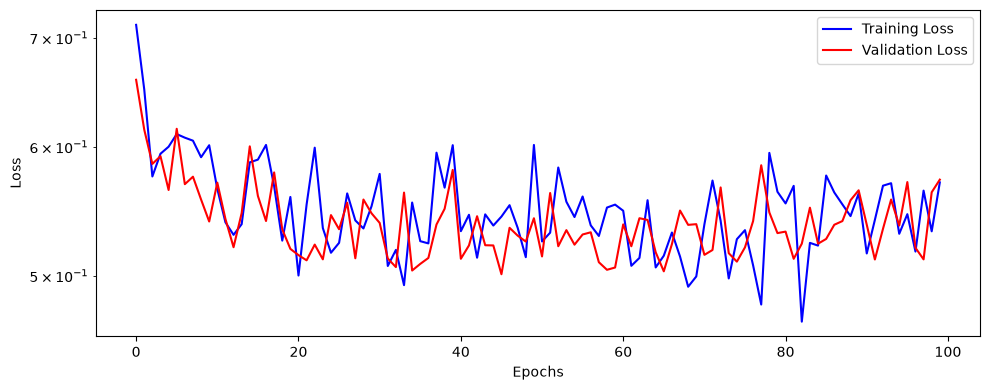

In [65]:
fig = tr_logistic.plot_losses()

Matriu de confusió:
[[ 8 12]
 [10 30]]


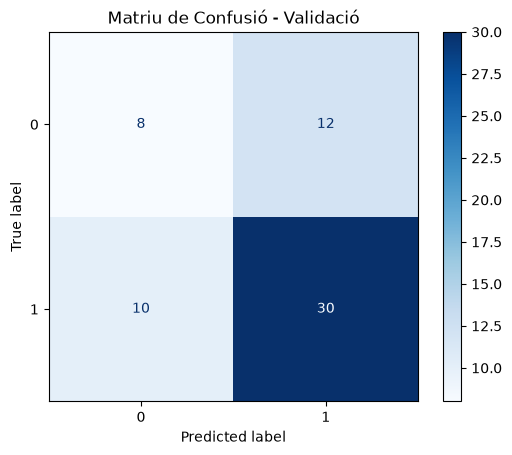

In [66]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_confusion_matrix():
    # 1. Posar el model en mode d'avaluació
    tr_logistic.model.eval()
    
    y_true = []
    y_pred = []
    
    # 2. Recórrer tot el val_loader sense calcular gradients
    with torch.no_grad():
        for x_batch, y_batch in tr_logistic.val_loader:
            # Enviar dades al mateix dispositiu (CPU o GPU) que el model
            x_batch = x_batch.to(tr_logistic.device)
            
            # Obtenir les prediccions del model
            yhat = tr_logistic.model(x_batch)
            
            # Si és regressió logística (classificació binaria):
            # Apliquem un llindar (threshold) de 0.5 per convertir probabilitats/logits a 0 o 1
            preds = (yhat >= 0.5).int()
            
            # Guardar les etiquetes reals i les prediccions (portant-les a CPU i numpy)
            y_true.extend(y_batch.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())
    
    # Convertir les llistes a arrays de NumPy
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # 3. Calcular la matriu de confusió
    cm = confusion_matrix(y_true, y_pred)
    print("Matriu de confusió:")
    print(cm)
    
    # 4. (Opcional) Visualitzar la matriu de confusió de manera gràfica
    plt.style.use('default')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Matriu de Confusió - Validació")
    plt.show()

plot_confusion_matrix()

Tant a l'entrenament com a la matriu de confusió es veuen les carències del model. Especialment es veu que falla a la classe 0 (línies horitzontals i verticals). El model intenta predir el 1. Per això es pot dir que té una precissió  $\frac{TP}{TP + FP} = \frac{39}{39 + 12} = \frac{39}{51} \approx \mathbf{0.7647}$ (76,47%) i una sensibilitat o `recall` de $\frac{TP}{TP + FN} = \frac{39}{39 + 1} = \frac{39}{40} = \mathbf{0.975}$ (97,5%). 

El recall per a la classe 0 és aproximadament del 40%

Falla precísament en la classe menys representada, però amb el `train_loader` balancejat per pesos no deuria passar. Anem a millorar el model. 

El model millorat incorpora dos capes ocultes lineals però amb funció d'activació `ReLu`. Es tracta de classificar una entrada de 25 valors de forma binària. La primera capa interpretarà l'entrada i aprendrà a treure informació de l'estructura de les dades. Aplica una `reducció de dimensionalitat`.  La segona sols té 5 entrades s'espera que el model aprenga a indicar per cadascuna alguna característica rellevant resumida de la capa d'entrada. La tercera capa ja treurà un número negatiu o positiu amb un perceptron lineal de sols 3 entrades que serà transformat en probabilitats per la capa sigmoide. 

> Per al problema és suficient, però s'ha fet una reducció de dimensionalitat molt agressiva i el model compta amb molt pocs paràmetres. 


In [73]:
lr = 0.1

torch.manual_seed(17)
# Now we can create a model
tr_logistic = nn.Sequential()
tr_logistic.add_module('flatten', nn.Flatten())
tr_logistic.add_module('hidden0', nn.Linear(25, 5, bias=False))
tr_logistic.add_module('activation0', nn.ReLU())
tr_logistic.add_module('hidden1', nn.Linear(5, 3, bias=False))
tr_logistic.add_module('activation1', nn.ReLU())
tr_logistic.add_module('output', nn.Linear(3, 1, bias=False))
tr_logistic.add_module('sigmoid', nn.Sigmoid())

# Defines a SGD optimizer to update the parameters
optimizer = optim.SGD(model_relu.parameters(), lr=lr)

# Defines a binary cross entropy loss function
binary_loss_fn = nn.BCELoss()




In [74]:
n_epochs = 100

tr_logistic = Trainer(model_relu, binary_loss_fn, optimizer)
tr_logistic.set_loaders(train_loader, val_loader)
tr_logistic.train(n_epochs)


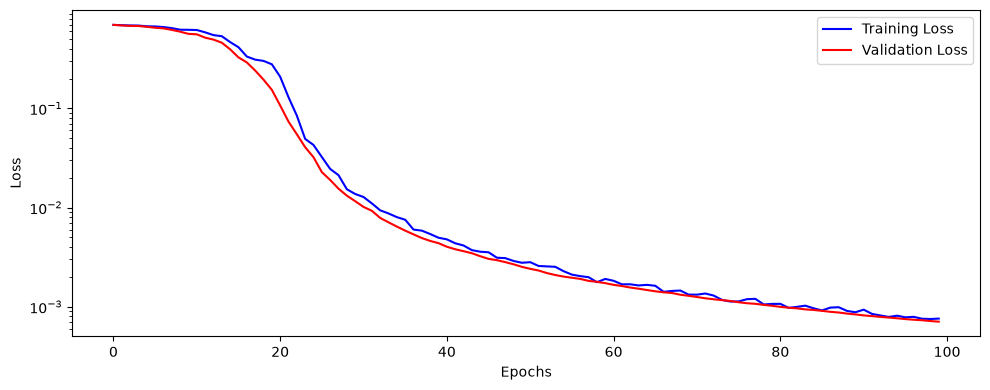

In [75]:
fig = tr_logistic.plot_losses()

Matriu de confusió:
[[20  0]
 [ 0 40]]


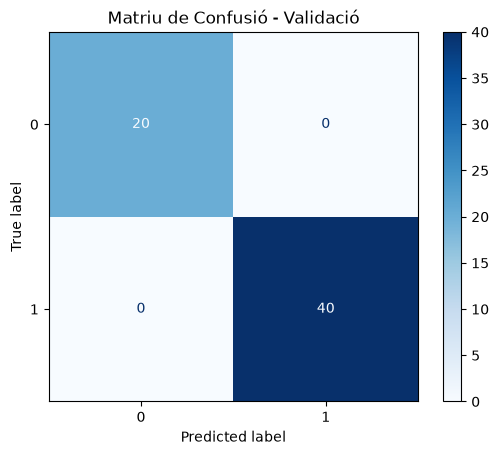

In [76]:
plot_confusion_matrix()

El resultat anterior és amb les dades d'entrenament i validació que s'han utilitzat per calcular la pèrdua. anem a provar realment amb dades noves. 

In [90]:
images_test, labels_test = generate_dataset(img_size=5, n_images=300, binary=True, seed=43)
x_tensor_test = torch.as_tensor(images_test / 255).float()

# Definim només la normalització
normalizer = Normalize(mean=(.5,), std=(.5,))

# Apliquem la transformació directament al tensor de test
x_tensor_test_norm = normalizer(x_tensor_test)

tr_logistic.model.eval()
with torch.no_grad():
    y_pred = tr_logistic.model(x_tensor_test_norm.to(tr_logistic.device))
    y_pred = y_pred.squeeze().cpu().numpy()
    y_pred = (y_pred >= 0.5)


Matriu de confusió:
[[ 90   0]
 [  0 210]]


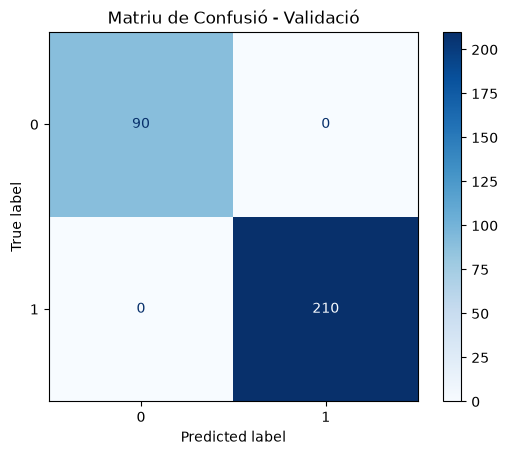

In [91]:
cm = confusion_matrix(labels_test, y_pred)
print("Matriu de confusió:")
print(cm)
    
plt.style.use('default')
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Matriu de Confusió - Validació")
plt.show()

El resultat és perfecte inclús en dades noves. També és veritat que es tracta d'imatges de sols 25 píxels i amb unes 20 combinacions possibles. El model possiblement ha memoritzat totes les possibilitats. 

## Xarxes convolucionals

L'exemple que hem vist aplana la imatge i la passa per capes lineals. Per al cas anterior ha funcionat bé. Però realment no està captant l'estructura 2D d'una imatge. Els píxels de la mateixa línia sí estan prop, però els de la segona línia estan molt pròxims als de la primera i queden molt separats. Una capa lineal totalment connectada pot aprendre patrons igualment, però a costa de entrenar molts pesos. És millor crear capes que interpreten les imatges com les `capes convolucionals`.

https://github.com/dvgodoy/PyTorchStepByStep/blob/master/Chapter05.ipynb 

## Mètriques i augmentació 

## Segmentation